# SAM3: Water Surfaces in Wildlife Camera Photos

Use the shared Drive shortcut for `water_surface_workshop.py`, `example_photos/`, and `sam3_model/`. You do not need to copy or upload the 7 GB of inputs. The notebook reads those shared files and writes preprocessing, masks, and results to your own `MyDrive/Workshop_Results/sam3` folder.

## 1. Runtime and Dependencies

**Local:** PyTorch `2.10.0+cu128` and Transformers `5.9.0`. Polygon drawing additionally requires `ipympl` and `ipywidgets`.

**Colab:** add the workshop folder as a shortcut under My Drive, select a GPU runtime, and run the setup cell to mount Drive. Make sure the shared folder is available to your account as a Viewer. The shared inputs stay read-only; results are saved in your personal Drive. No model or image copies are required.

In [1]:
import importlib.util

try:
    IN_COLAB = importlib.util.find_spec('google.colab') is not None
except ModuleNotFoundError:
    IN_COLAB = False

INSTALL_COLAB_PACKAGES = True
INSTALL_POLYGON_WIDGETS = True

if IN_COLAB and INSTALL_COLAB_PACKAGES:
    %pip install --upgrade transformers==5.9.0 accelerate pillow numpy pandas huggingface_hub ipywidgets ipympl
elif INSTALL_POLYGON_WIDGETS:
    %pip install --upgrade ipympl ipywidgets

if IN_COLAB:
    from google.colab import drive, output

    output.enable_custom_widget_manager()
    drive.mount('/content/drive')

# Optional Hugging Face authentication:
# from huggingface_hub import notebook_login
# notebook_login()

  Using cached huggingface_hub-2.4.0-py3-none-any.whl.metadata (16 kB)
Mounted at /content/drive


## 2. Paths and Configuration

`PROJECT_ROOT` points to the shared workshop folder containing `example_photos/` and `sam3_model/`. Change its path if your Drive shortcut has a different name. `PERSONAL_OUTPUT_ROOT` points to your writable My Drive, so the shared input folder is never modified.

All segmentation images must be 640 pixels wide. This version uses a user-drawn polygon as the reference; it does not expand the largest mask.

In [2]:
from pathlib import Path
import inspect
import json
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from IPython.display import display

PROJECT_ROOT = Path(
    '/content/drive/MyDrive/'
    'Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery'
) if IN_COLAB else Path.cwd()
PERSONAL_OUTPUT_ROOT = (
    Path('/content/drive/MyDrive/Workshop_Results')
    if IN_COLAB else PROJECT_ROOT / 'workshop_outputs'
)
assert (PROJECT_ROOT / 'water_surface_workshop.py').is_file(), 'Set PROJECT_ROOT to the shared workshop folder.'
sys.path.insert(0, str(PROJECT_ROOT))
from water_surface_workshop import (
    EXTENSIONS, image_paths, load_rgb, preprocess_case1, load_sam3,
    segment_water, segment_folder, overlay_mask, timestamp_from_name,
    largest_water_mask, row_fractions,
    calculate_time_series, plot_time_series,
)

CASE1 = PROJECT_ROOT / 'example_photos' / 'case1'
OUTPUT = PERSONAL_OUTPUT_ROOT / 'sam3'
PREPROCESSED = OUTPUT / 'case1' / 'preprocess'
CASE2 = PROJECT_ROOT / 'example_photos' / 'case2'
CASE2_OUTPUT = OUTPUT / 'case2'
POLYGON_OUTPUT = OUTPUT / 'case2_polygon'
MODEL_PATHS = (PROJECT_ROOT / 'sam3_model', PROJECT_ROOT / 'models' / 'sam3_model')
MODEL_PATH = next((path for path in MODEL_PATHS if (path / 'config.json').is_file()), None)
if MODEL_PATH is None:
    raise FileNotFoundError(f'Could not find SAM3 model config at any of: {MODEL_PATHS}')
MODEL_ID = str(MODEL_PATH)
TEXT_PROMPT = 'water'
DETECTION_THRESHOLD = 0.5
MASK_THRESHOLD = 0.5
WIDTH = 640
CHANNEL_TOLERANCE = 10
GRAYSCALE_CUTOFF = 0.98
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
print('Shared inputs:', PROJECT_ROOT)
print('SAM3 model:', MODEL_PATH)
print('Personal outputs:', OUTPUT)
print('PyTorch:', torch.__version__, '| Transformers:', transformers.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Unavailable: CPU inference will be slow')
print('Case1:', len(image_paths(CASE1)), '| Case2:', len(image_paths(CASE2)))

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Shared inputs: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery
SAM3 model: /content/drive/MyDrive/Part 1, Module 2: Surface Water Dynamics from Wildlife Camera Imagery/sam3_model
Personal outputs: /content/drive/MyDrive/Workshop_Results/sam3
PyTorch: 2.11.0+cu130 | Transformers: 5.9.0
GPU: Tesla T4
Case1: 3 | Case2: 64


## 3. Camera Timestamps

These files encode time as `..._YYYYMMDD_HHMMSSPST-burst.png`. We use that explicit camera timestamp, not file modification time or an assumed EXIF date. The `PST` label is preserved as camera-local time, without applying daylight-saving or timezone conversions. A missing or malformed timestamp raises an error so photos cannot silently disappear from the time series. Photos with the same timestamp are burst replicates, not separate observation times.

In [3]:
timestamp_check = pd.DataFrame([
    {'filename': path.name, 'timestamp': timestamp_from_name(path.name)}
    for path in image_paths(CASE2)
])
display(timestamp_check.head())
print('Unique observation times:', timestamp_check['timestamp'].nunique())

,filename,timestamp
0,RMP_S32_20231001_090002PST-1.png,2023-10-01 09:00:02
1,RMP_S32_20231001_090002PST-2.png,2023-10-01 09:00:02
2,RMP_S32_20231001_090002PST-3.png,2023-10-01 09:00:02
3,RMP_S32_20231001_090002PST-4.png,2023-10-01 09:00:02
4,RMP_S32_20231001_090002PST-5.png,2023-10-01 09:00:02


Unique observation times: 13


## 4. Case1: Filter Night Vision, Resize, and Inspect

For each original RGB pixel, calculate `max(R,G,B) - min(R,G,B)`. A pixel is nearly gray when this difference is at most `CHANNEL_TOLERANCE` (default 10). Reject a photo if at least `GRAYSCALE_CUTOFF` (default 98%) of its pixels are nearly gray.

Retained photos are resized to width 640, preserving aspect ratio, and saved under your personal `Workshop_Results/sam3/case1/preprocess` folder. The shared originals are not changed.

,filename,grayscale_fraction,status,original_width,original_height,output_width,output_height,output_path
0,RMP_S30R_20230718_001346PST-5.JPG,1.000000,night_vision,9040,5072,NaN,NaN,
1,RMP_S30R_20230718_041346PST-1.JPG,0.591411,kept,9040,5072,640.0,359.0,/content/drive/MyDrive/Workshop_Results/sam3/c...
2,RMP_S30R_20231021_170820PST-3.JPG,0.194921,kept,9040,5072,640.0,359.0,/content/drive/MyDrive/Workshop_Results/sam3/c...


status
kept            2
night_vision    1


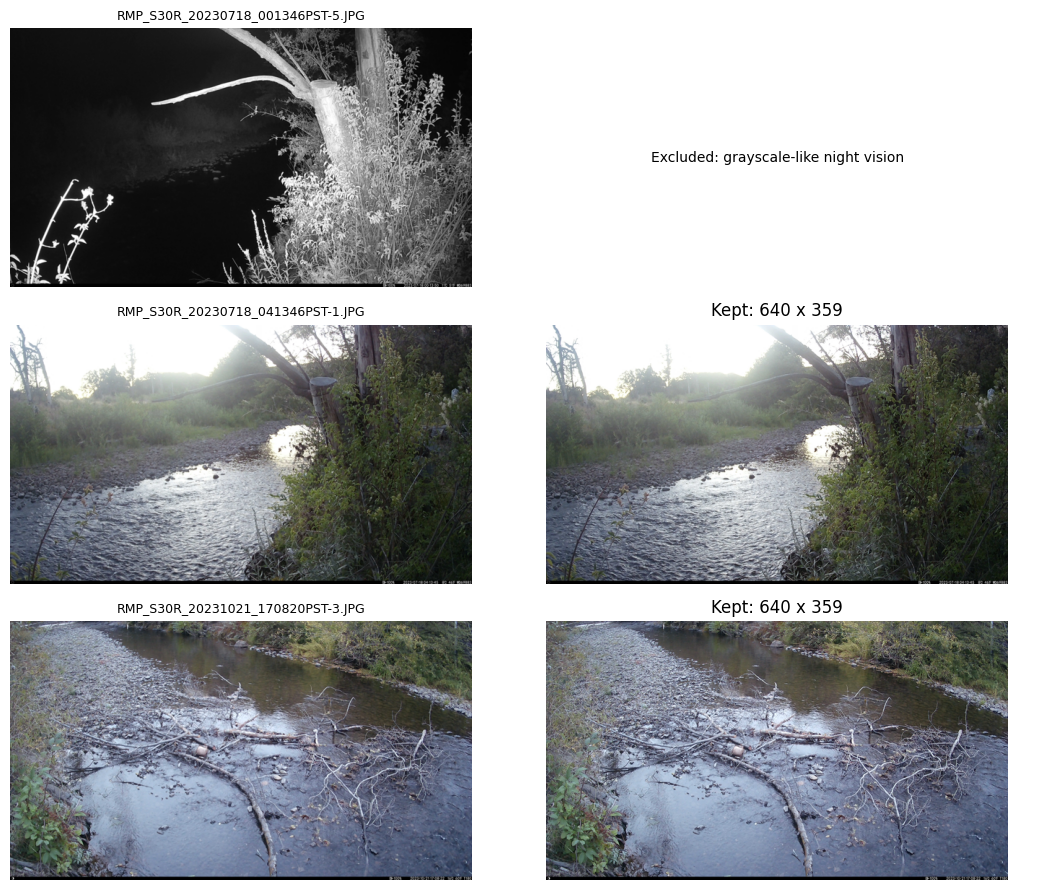

In [4]:
preprocess_report = preprocess_case1(
    CASE1, WIDTH, CHANNEL_TOLERANCE, GRAYSCALE_CUTOFF, output_dir=PREPROCESSED
)
display(preprocess_report)
print(preprocess_report['status'].value_counts().to_string())

figure, axes = plt.subplots(len(preprocess_report), 2,
                            figsize=(11, 3 * len(preprocess_report)), squeeze=False)
for row_number, record in enumerate(preprocess_report.to_dict('records')):
    original = load_rgb(CASE1 / record['filename'])
    original.thumbnail((640, 640))
    axes[row_number, 0].imshow(original)
    axes[row_number, 0].set_title(record['filename'], fontsize=9)
    if record['status'] == 'kept':
        resized = load_rgb(record['output_path'])
        assert resized.width == WIDTH
        axes[row_number, 1].imshow(resized)
        axes[row_number, 1].set_title(f'Kept: {resized.width} x {resized.height}')
    else:
        axes[row_number, 1].text(0.5, 0.5, 'Excluded: grayscale-like night vision',
                                 ha='center', va='center', wrap=True)
    for axis in axes[row_number]:
        axis.axis('off')
figure.tight_layout()
plt.show()

## 5. Load SAM3 and Inspect Inference

SAM3 receives the image and the text prompt **water**. `DETECTION_THRESHOLD` controls which instances are accepted; `MASK_THRESHOLD` binarizes their pixels. The processor resizes predictions back to the input image size, and we union all accepted water instances.

The cell displays the actual inference function from the companion module. No accepted instances produces an empty mask. An inference error raises an exception, rather than inventing a zero result. Model loading may download several gigabytes on the first run. If you see an access error, accept the model terms and use the optional login in section 1, then retry.

def segment_water(image, model, processor, device, text='water',
                  detection_threshold=0.5, mask_threshold=0.5):
    import torch

    inputs = processor(images=image, text=text, return_tensors='pt')
    inputs = {key: value.to(device) if isinstance(value, torch.Tensor) else value
              for key, value in inputs.items()}
    with torch.inference_mode():
        outputs = model(**inputs)
    result = processor.post_process_instance_segmentation(
        outputs, threshold=detection_threshold, mask_threshold=mask_threshold,
        target_sizes=inputs['original_sizes'].tolist(),
    )[0]
    combined = np.zeros((image.height, image.width), dtype=bool)
    for mask in result['masks']:
        values = mask.detach().cpu().numpy() if isinstance(mask, torch.Tensor) else np.asarray(mask)
        values = np.squeeze(values)
        if values.shape != combined.shape:
            raise ValueError(f'Unexpected mask shape: {values.shape}')
        combined |= values > 0
    

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

[1/2] RMP_S30R_20230718_041346PST-1.JPG.png: 0.1977
[2/2] RMP_S30R_20231021_170820PST-3.JPG.png: 0.3206


,filename,water_fraction,detection_status
0,RMP_S30R_20230718_041346PST-1.JPG.png,0.197654,water
1,RMP_S30R_20231021_170820PST-3.JPG.png,0.320552,water


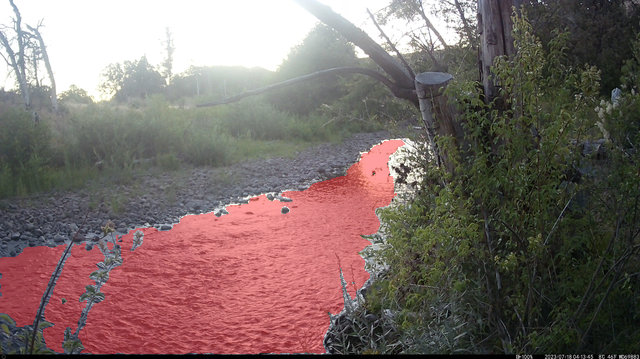

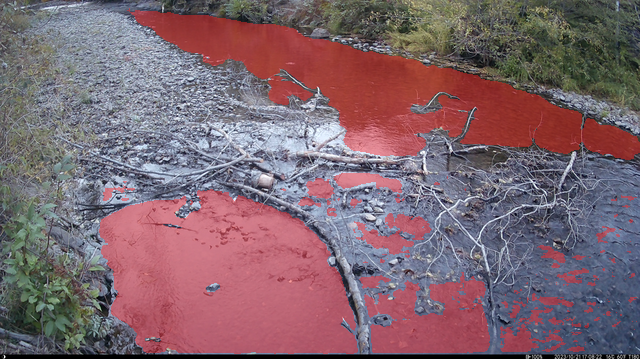

In [ ]:
print(inspect.getsource(segment_water))
model, processor, device = load_sam3(MODEL_ID)
case1_table = segment_folder(PREPROCESSED, OUTPUT / 'case1', model, processor, device,
                             TEXT_PROMPT, DETECTION_THRESHOLD, MASK_THRESHOLD)
display(case1_table[['filename', 'water_fraction', 'detection_status']])
for record in case1_table.to_dict('records'):
    display(overlay_mask(load_rgb(record['image_path']),
                         np.load(record['mask_path'], allow_pickle=False)))

## 6. Case2: Segment Every Photo and Select the Largest

Case2 is already preprocessed. The cell checks that every photo is 640 wide and that all have the same dimensions **before** model inference. It processes all images, saves binary `.npy` masks and red overlays, and computes

$$f_i = \frac{\text{water-mask pixels in photo }i}{H_i W_i}.$$

The photo maximizing $f_i$ supplies the initial reference.

[1/64] RMP_S32_20231001_090002PST-1.png: 0.1950
[2/64] RMP_S32_20231001_090002PST-2.png: 0.1934
[3/64] RMP_S32_20231001_090002PST-3.png: 0.1937
[4/64] RMP_S32_20231001_090002PST-4.png: 0.1964
[5/64] RMP_S32_20231001_090002PST-5.png: 0.1943
[6/64] RMP_S32_20231001_110002PST-1.png: 0.1846
[7/64] RMP_S32_20231001_110002PST-2.png: 0.1900
[8/64] RMP_S32_20231001_110002PST-3.png: 0.1915
[9/64] RMP_S32_20231001_110002PST-4.png: 0.1877
[10/64] RMP_S32_20231001_110002PST-5.png: 0.1902
[11/64] RMP_S32_20231001_150002PST-1.png: 0.1805
[12/64] RMP_S32_20231001_150002PST-2.png: 0.1787
[13/64] RMP_S32_20231001_150002PST-3.png: 0.1804
[14/64] RMP_S32_20231001_150002PST-4.png: 0.1812
[15/64] RMP_S32_20231001_150002PST-5.png: 0.1756
[16/64] RMP_S32_20231001_170002PST-1.png: 0.1482
[17/64] RMP_S32_20231001_170002PST-2.png: 0.1405
[18/64] RMP_S32_20231001_170002PST-3.png: 0.1423
[19/64] RMP_S32_20231001_170002PST-4.png: 0.1427
[20/64] RMP_S32_20231001_170002PST-5.png: 0.1519
[21/64] RMP_S32_20231002_0700

,filename,image_path,timestamp,mask_path,water_pixels,image_pixels,water_fraction,detection_status
0,RMP_S32_20231001_090002PST-1.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/sam3/c...,44806,229760,0.195012,water
1,RMP_S32_20231001_090002PST-2.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/sam3/c...,44443,229760,0.193432,water
2,RMP_S32_20231001_090002PST-3.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/sam3/c...,44504,229760,0.193698,water
3,RMP_S32_20231001_090002PST-4.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/sam3/c...,45131,229760,0.196427,water
4,RMP_S32_20231001_090002PST-5.png,"/content/drive/MyDrive/Part 1, Module 2: Surfa...",2023-10-01 09:00:02,/content/drive/MyDrive/Workshop_Results/sam3/c...,44642,229760,0.194298,water


detection_status
water    64
Largest: RMP_S32_20231002_090002PST-5.png | water area fraction: 0.19983896239554316


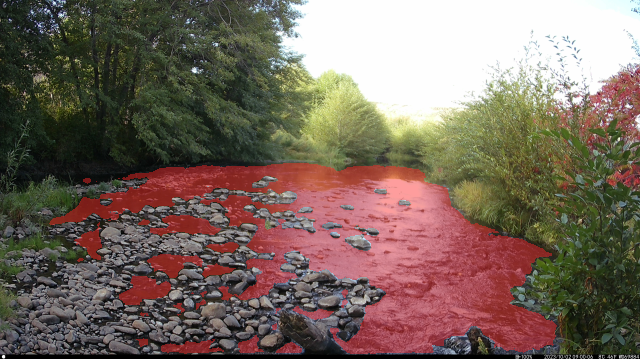

In [6]:
case2_paths = image_paths(CASE2)
case2_sizes = {load_rgb(path).size for path in case2_paths}
assert len(case2_sizes) == 1, f'Case2 images must share one shape: {case2_sizes}'
assert next(iter(case2_sizes))[0] == WIDTH == 640
case2_table = segment_folder(CASE2, CASE2_OUTPUT, model, processor, device,
                             TEXT_PROMPT, DETECTION_THRESHOLD, MASK_THRESHOLD)
display(case2_table.head())
print(case2_table['detection_status'].value_counts().to_string())
largest_record, largest_mask = largest_water_mask(case2_table)
np.save(CASE2_OUTPUT / 'largest_original_mask.npy', largest_mask)
print('Largest:', largest_record['filename'], '| water area fraction:', largest_record['water_fraction'])
largest_image = load_rgb(largest_record['image_path'])
display(overlay_mask(largest_image, largest_mask))

## 7. Draw the Polygon Reference and Calculate Row Fractions

The largest original SAM3 mask is a **visual guide only**. Draw the desired maximum water-surface region on its photo. The filled polygon, including its boundary, defines the reference. Keep the camera position, crop, and scale fixed across photos.

For each photo mask $M_i$ and your polygon mask $R$:

$$q_{i,r}=\frac{|M_{i,r}\cap R_r|}{|R_r|},\qquad Q_i=\frac{1}{|V|}\sum_{r\in V}q_{i,r},\qquad V=\{r:|R_r|>0\}.$$

Only rows containing polygon pixels are averaged. Every such row receives equal weight; this is not a ratio of total areas. Water outside your polygon is ignored, and fractions are bounded by 0 and 1.

In [7]:
def polygon_to_mask(vertices, shape):
    from PIL import Image, ImageDraw

    points = np.asarray(vertices, dtype=float)
    if points.ndim != 2 or points.shape[1] != 2 or len(points) < 3:
        raise ValueError('Draw a polygon with at least three vertices.')
    if not np.isfinite(points).all() or len(np.unique(points, axis=0)) < 3:
        raise ValueError('Polygon vertices must be finite and distinct.')
    height, width = shape
    if ((points[:, 0] < 0).any() or (points[:, 0] > width - 1).any()
            or (points[:, 1] < 0).any() or (points[:, 1] > height - 1).any()):
        raise ValueError('Keep all polygon vertices inside the image.')
    area = abs(np.dot(points[:, 0], np.roll(points[:, 1], 1))
               - np.dot(points[:, 1], np.roll(points[:, 0], 1))) / 2
    if area < 1:
        raise ValueError('Draw a nondegenerate polygon with an area of at least one pixel.')
    canvas = Image.new('L', (width, height), 0)
    ImageDraw.Draw(canvas).polygon([tuple(point) for point in points], fill=1)
    mask = np.asarray(canvas, dtype=bool)
    if not mask.any():
        raise ValueError('The polygon reference is empty.')
    return mask


def run_analysis(vertices):
    from IPython.display import Image as NotebookImage
    from matplotlib.patches import Patch, Polygon

    reference = polygon_to_mask(vertices, largest_mask.shape)
    POLYGON_OUTPUT.mkdir(parents=True, exist_ok=True)
    photos, times, rows = calculate_time_series(case2_table, reference, POLYGON_OUTPUT)
    photos = photos.drop(columns=['expansion_pixels'])
    photos.to_csv(POLYGON_OUTPUT / 'photo_fractions.csv', index=False)
    np.save(POLYGON_OUTPUT / 'largest_original_mask.npy', largest_mask)
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(10, 5))
        axis.imshow(overlay_mask(largest_image, reference, color=(0, 210, 210)))
        axis.add_patch(Polygon(vertices, closed=True, fill=False, edgecolor='cyan', linewidth=2))
        axis.set_title('User-drawn polygon reference')
        axis.legend(handles=[Patch(facecolor='cyan', label='Polygon reference')], loc='lower right')
        axis.axis('off')
        figure.tight_layout()
        figure.savefig(POLYGON_OUTPUT / 'reference_polygon.png', dpi=180)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'reference_polygon.png')))
        plt.close(figure)
        figure = plot_time_series(photos, times, POLYGON_OUTPUT)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'water_fraction_vs_time.png')))
        plt.close(figure)
        figure, axis = plt.subplots(figsize=(12, 3))
        axis.scatter(photos['timestamp'], photos['water_fraction'], s=10, alpha=0.4)
        axis.set(xlabel='Camera time (PST label)', ylabel='Water / whole image', ylim=(0, 1))
        figure.autofmt_xdate()
        figure.tight_layout()
        figure.savefig(POLYGON_OUTPUT / 'water_area_fraction_vs_time.png', dpi=180)
        display(NotebookImage(filename=str(POLYGON_OUTPUT / 'water_area_fraction_vs_time.png')))
        plt.close(figure)
    polygon_data = {
        'vertices_xy': np.asarray(vertices, dtype=float).tolist(),
        'image_shape': list(reference.shape),
        'source_image': str(largest_record['filename']),
        'coordinate_system': '640-wide image pixels; x rightward, y downward, origin at top left',
        'rasterization': 'Pillow ImageDraw polygon; filled interior and boundary',
    }
    (POLYGON_OUTPUT / 'polygon_reference.json').write_text(json.dumps(polygon_data, indent=2), encoding='utf-8')
    metadata = {
        'model_id': MODEL_ID,
        'model_revision': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
        'text_prompt': TEXT_PROMPT,
        'detection_threshold': DETECTION_THRESHOLD,
        'mask_threshold': MASK_THRESHOLD,
        'channel_tolerance': CHANNEL_TOLERANCE,
        'grayscale_cutoff': GRAYSCALE_CUTOFF,
        'largest_source': str(largest_record['filename']),
        'largest_area_fraction': float(largest_record['water_fraction']),
        'reference_type': 'user_polygon',
        'reference_shape': list(reference.shape),
        'reference_pixels': int(reference.sum()),
        'reference_rows': int(reference.any(axis=1).sum()),
        'photo_count': len(photos),
        'timestamp_count': len(times),
        'torch': torch.__version__,
        'transformers': transformers.__version__,
        'seed': 42,
        'metric': 'mean over nonempty polygon rows of water intersection / polygon pixels',
        'timestamp_basis': 'filename camera-local PST label; no timezone conversion',
    }
    (POLYGON_OUTPUT / 'analysis_settings.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
    display(photos[['filename', 'timestamp', 'water_fraction', 'mean_row_fraction']].head())
    print('Saved polygon analysis to', POLYGON_OUTPUT)
    return photos, times, reference

### 8. Draw and Apply the Reference

Run the next cell to open the interactive drawing canvas. Red marks the largest SAM3 water mask. Click consecutive vertices around the desired reference region, then click the first vertex to close the polygon. Keep all vertices inside the image and draw a simple, non-crossing outline. Cyan shading previews the polygon reference.

Drag a completed polygon's handles to adjust it. The Apply and save button becomes available only for a valid polygon. Click it to calculate all photo fractions and save the reference, vertices, settings, and plots. Drawing or editing alone does not overwrite saved analysis. Clear polygon starts a new outline without changing previous saved files.

This step intentionally waits for your input; Run All cannot choose a polygon for you. No additional SAM3 inference is needed when you redraw the reference. Rerunning the drawing cell clears the current drawing state. Coordinates are in the original 640-wide image pixel space, with x rightward and y downward.

HTML(value='Draw a polygon, then close it by clicking its first vertex.')

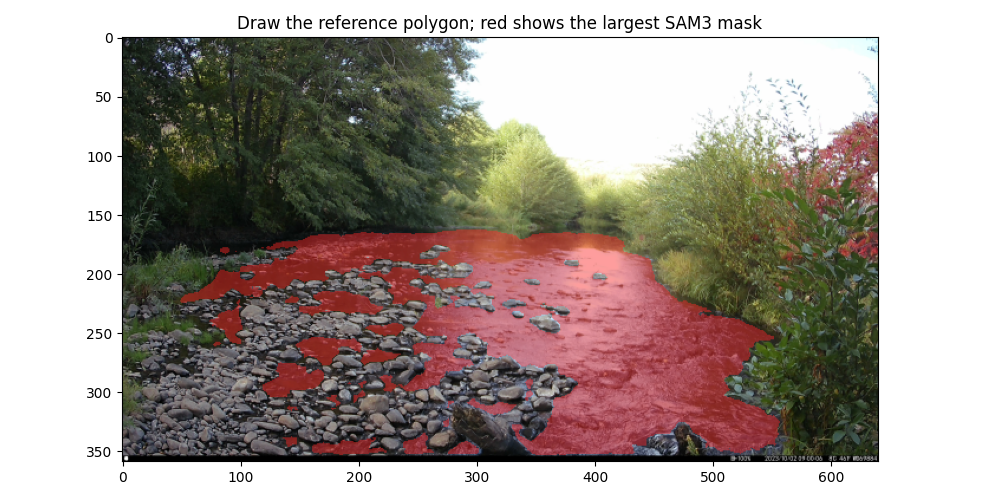

Output()

In [8]:
import ipywidgets as widgets

if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

%matplotlib widget

import matplotlib.pyplot as plt
from matplotlib.widgets import PolygonSelector

polygon_vertices = []
pending_reference_mask = None
reference_mask = None
polygon_analysis_saved = False
apply_button = widgets.Button(description='Apply and save', icon='save', disabled=True)
reset_button = widgets.Button(description='Clear polygon', icon='eraser')
status = widgets.HTML(value='Draw a polygon, then close it by clicking its first vertex.')
analysis_output = widgets.Output()

with plt.ioff():
    drawing_figure, drawing_axis = plt.subplots(figsize=(10, 5))
drawing_axis.imshow(overlay_mask(largest_image, largest_mask))
polygon_overlay = np.zeros((*largest_mask.shape, 4), dtype=np.uint8)
reference_artist = drawing_axis.imshow(polygon_overlay)
drawing_axis.set_title('Draw the reference polygon; red shows the largest SAM3 mask')
drawing_axis.set_xlim(-0.5, largest_image.width - 0.5)
drawing_axis.set_ylim(largest_image.height - 0.5, -0.5)
drawing_axis.set_aspect('equal')
drawing_figure.tight_layout()
drawing_figure.canvas.toolbar_visible = False


def select_reference(vertices):
    global polygon_vertices, pending_reference_mask, polygon_analysis_saved
    polygon_analysis_saved = False
    apply_button.disabled = True
    try:
        pending_reference_mask = polygon_to_mask(vertices, largest_mask.shape)
    except ValueError as error:
        pending_reference_mask = None
        polygon_vertices = []
        status.value = str(error)
        return
    polygon_vertices = np.asarray(vertices, dtype=float).tolist()
    polygon_overlay[:] = 0
    polygon_overlay[pending_reference_mask] = (0, 210, 210, 95)
    reference_artist.set_data(polygon_overlay)
    drawing_figure.canvas.draw_idle()
    apply_button.disabled = False
    status.value = (f'Polygon ready: {len(polygon_vertices)} vertices, '
                    f'{int(pending_reference_mask.sum())} reference pixels. Click Apply and save.')


polygon_selector = PolygonSelector(drawing_axis, select_reference,
                                   props={'color': 'cyan', 'linewidth': 2},
                                   handle_props={'markerfacecolor': 'cyan'})


def clear_polygon(button):
    global polygon_vertices, pending_reference_mask, polygon_analysis_saved
    polygon_selector.clear()
    polygon_vertices = []
    pending_reference_mask = None
    polygon_analysis_saved = False
    polygon_overlay[:] = 0
    reference_artist.set_data(polygon_overlay)
    drawing_figure.canvas.draw_idle()
    apply_button.disabled = True
    status.value = 'Draw a new polygon. Previous saved files are unchanged until Apply and save.'


def apply_polygon(button):
    global photo_fractions, timestamp_fractions, reference_mask, polygon_analysis_saved
    apply_button.disabled = True
    with analysis_output:
        analysis_output.clear_output(wait=True)
        try:
            photo_fractions, timestamp_fractions, reference_mask = run_analysis(polygon_vertices)
        except Exception:
            polygon_analysis_saved = False
            status.value = 'Analysis failed; inspect the error below. No successful result is being claimed.'
            raise
        else:
            polygon_analysis_saved = True
            status.value = f'Polygon analysis saved to {POLYGON_OUTPUT}.'
        finally:
            apply_button.disabled = pending_reference_mask is None


apply_button.on_click(apply_polygon)
reset_button.on_click(clear_polygon)
display(status)
display(drawing_figure.canvas)
display(widgets.HBox([reset_button, apply_button]))
display(analysis_output)
drawing_figure.canvas.draw()

## 9. Outputs

Inputs and the local SAM3 model are read from the shared folder. All writable outputs are saved to your personal `MyDrive/Workshop_Results/sam3` folder:

- `case1/preprocess/`: resized case1 photos and the preprocessing report.
- `case1/` and `case2/`: masks, overlays, and segmentation-summary CSVs.
- `case2_polygon/`: the applied reference mask, polygon vertices, row/photo/timestamp CSVs, settings, and plots.

The shared folder stays read-only. No participant needs to copy the images or model to their Drive.

In [9]:
if not polygon_analysis_saved:
    print('Draw a polygon and click Apply and save before validating or downloading results.')
else:
    required_outputs = ['largest_original_mask.npy', 'reference_mask.npy',
                        'polygon_reference.json', 'reference_polygon.png',
                        'photo_fractions.csv', 'row_fractions.csv',
                        'timestamp_fractions.csv', 'water_fraction_vs_time.png',
                        'water_area_fraction_vs_time.png', 'analysis_settings.json']
    assert all((POLYGON_OUTPUT / name).is_file() for name in required_outputs)
    assert len(photo_fractions) == len(case2_paths)
    assert photo_fractions['mean_row_fraction'].between(0, 1).all()
    assert reference_mask.shape == largest_mask.shape
    print('Complete:', len(photo_fractions), 'photos;', len(timestamp_fractions), 'timestamps')
    display(timestamp_fractions.head())

Complete: 64 photos; 13 timestamps


,timestamp,mean_row_fraction,photo_count
0,2023-10-01 09:00:02,0.420772,5
1,2023-10-01 11:00:02,0.415030,5
2,2023-10-01 15:00:02,0.392128,5
3,2023-10-01 17:00:02,0.300630,5
4,2023-10-02 07:00:02,0.385528,5
